In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Mapping_Feature_Drift"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
ACTIVATIONS_DIR = os.path.join(DATA_DIR, "activations")

SAE_V2_DIR = os.path.join(PROJECT_DIR, "sae_research_100k_v2")

CHECKPOINT_DIR = SAE_V2_DIR
EVALUATION_DIR = os.path.join(SAE_V2_DIR, "controlled_evaluation_v2")

os.makedirs(EVALUATION_DIR, exist_ok=True)

print("Drive mounted successfully.")
print("Project directory:", PROJECT_DIR)
print("SAE checkpoints:", CHECKPOINT_DIR)

Drive mounted successfully.
Project directory: /content/drive/MyDrive/Mapping_Feature_Drift
SAE checkpoints: /content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2


In [6]:
from google.colab import drive

# Disconnect the currently mounted account
drive.flush_and_unmount()

# Reconnect
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [17]:
import glob
import os

checkpoints = glob.glob(
    os.path.join(CHECKPOINT_DIR, "sae_layer_*.pt")
)

assert len(checkpoints) == 36

for layer in range(1, 37):
    path = os.path.join(
        CHECKPOINT_DIR,
        f"sae_layer_{layer:02d}.pt"
    )
    assert os.path.isfile(path), f"Missing layer {layer}"

print("All 36 SAE checkpoints verified.")

All 36 SAE checkpoints verified.


In [7]:

# ================================================================
# MAPPING FEATURE DRIFT
# EXPERIMENT 1: CROSS-LAYER FEATURE DRIFT
# Qwen2.5-3B Base | 36 Layers | Top-K SAE | 5 Epoch Checkpoints
#
# Validation + Held-out Test
# Hungarian matching + Pearson correlation
# ================================================================

import os, gc, json, glob, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings("ignore")

# ---------------------- CONFIGURATION ---------------------------


# ---------------------- CONFIGURATION ---------------------------

from google.colab import drive

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# Correct complete shared project directory
ROOT = "/content/drive/MyDrive/Mapping_Feature_Drift"

SAE_DIR = os.path.join(ROOT, "sae_research_100k_v2")

# Actual checkpoint location confirmed by Colab
CHECKPOINT_DIR = os.path.join(SAE_DIR, "saes")

# Controlled benchmark dataset
DATASET_PATH = os.path.join(
    ROOT,
    "data",
    "datasets",
    "qwen_feature_drift_controlled_v1.csv"
)

# Experiment outputs will be saved alongside the v2 SAEs
OUTPUT_DIR = os.path.join(
    SAE_DIR,
    "experiment_01_feature_drift"
)

PROFILE_DIR = os.path.join(
    OUTPUT_DIR,
    "feature_profiles"
)

MODEL_ID = "Qwen/Qwen2.5-3B"
REVISION = "3aab1f1954e9cc14eb9509a215f9e5ca08227a9b"

D_MODEL = 2048
D_SAE = 8192
TOP_K = 32
N_LAYERS = 36

BATCH_SIZE = 2
MAX_LENGTH = 128
TOP_FEATURES = 256
THRESHOLDS = [0.70, 0.80]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------- INPUT VALIDATION ------------------------

assert DEVICE == "cuda", "Enable a Colab GPU runtime."

assert os.path.isdir(ROOT), \
    f"Project directory not found: {ROOT}"

assert os.path.isfile(DATASET_PATH), \
    f"Controlled dataset not found: {DATASET_PATH}"

assert os.path.isdir(CHECKPOINT_DIR), \
    f"SAE checkpoint directory not found: {CHECKPOINT_DIR}"

checkpoint_paths = [
    os.path.join(
        CHECKPOINT_DIR,
        f"sae_layer_{layer:02d}.pt"
    )
    for layer in range(1, N_LAYERS + 1)
]

missing = [
    path for path in checkpoint_paths
    if not os.path.isfile(path)
]

assert not missing, \
    f"Missing {len(missing)} SAE checkpoints: {missing[:5]}"

print("GPU:", torch.cuda.get_device_name(0))
print("Project:", ROOT)
print("Dataset:", DATASET_PATH)
print("SAE checkpoints:", len(checkpoint_paths))

# Create output folders ONLY after verifying all inputs.
os.makedirs(PROFILE_DIR, exist_ok=True)

print("Output:", OUTPUT_DIR)
print("Research environment verified successfully.")


# ---------------------- DATASET ---------------------------------

df = pd.read_csv(DATASET_PATH)

assert {"text", "adjective", "split"}.issubset(df.columns)

df["split"] = df["split"].astype(str).str.lower()

splits = {
    "validation": df[df["split"].isin(["validation", "val"])].copy(),
    "test": df[df["split"] == "test"].copy()
}

for name, part in splits.items():
    print(f"{name}: {len(part)} examples")
    assert len(part) > 0, f"Missing {name} examples."

# ---------------------- SAE ARCHITECTURE ------------------------

class TopKSAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Linear(D_MODEL, D_SAE)
        self.decoder = nn.Linear(D_SAE, D_MODEL)

        self.register_buffer(
            "activation_mean",
            torch.zeros(D_MODEL)
        )

    def encode(self, x):
        centered = x - self.activation_mean

        pre = self.encoder(centered)
        positive = F.relu(pre)

        values, indices = torch.topk(
            positive, TOP_K, dim=-1
        )

        sparse = torch.zeros_like(positive)
        sparse.scatter_(-1, indices, values)

        return sparse

    def forward(self, x):
        z = self.encode(x)
        return self.decoder(z) + self.activation_mean


def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        for key in ["state_dict", "model_state_dict", "sae_state_dict"]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                return checkpoint[key]

    return checkpoint


def load_sae(layer):
    path = os.path.join(
        CHECKPOINT_DIR,
        f"sae_layer_{layer:02d}.pt"
    )

    assert os.path.isfile(path), f"Missing SAE layer {layer}"

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )

    state = extract_state_dict(checkpoint)

    # Handle common DataParallel prefixes.
    state = {
        k.removeprefix("module."): v
        for k, v in state.items()
    }

    sae = TopKSAE()

    try:
        sae.load_state_dict(state, strict=True)
    except Exception as exc:
        raise RuntimeError(
            f"Checkpoint architecture mismatch at layer {layer}.\n"
            f"Available keys: {list(state.keys())[:20]}"
        ) from exc

    sae.eval().to(DEVICE)

    return sae


print("\nVerifying all 36 SAE checkpoints...")

# Verify checkpoint architecture before expensive model extraction.
for layer in tqdm(range(1, N_LAYERS + 1)):
    sae = load_sae(layer)
    del sae

gc.collect()
torch.cuda.empty_cache()

print("All checkpoint architectures verified.")

# ---------------------- TOKENIZER AND MODEL ---------------------

print("\nLoading Qwen2.5-3B Base...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    trust_remote_code=True
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True,
    trust_remote_code=True
)

model.eval().to(DEVICE)

assert len(model.model.layers) == N_LAYERS

print("Model loaded:", MODEL_ID)
print("Transformer layers:", len(model.model.layers))

# ---------------------- TOKEN ALIGNMENT -------------------------

def get_adjective_positions(texts, adjectives):
    encoded = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_offsets_mapping=True,
        return_tensors="pt"
    )

    offsets = encoded.pop("offset_mapping").numpy()

    positions = []

    for i, adjective in enumerate(adjectives):
        start = texts[i].lower().find(str(adjective).lower())

        if start < 0:
            raise ValueError(
                f"Could not locate adjective {adjective!r} "
                f"in {texts[i]!r}"
            )

        end = start + len(str(adjective))

        token_indices = [
            j for j, (a, b) in enumerate(offsets[i])
            if b > start and a < end and b > a
        ]

        if not token_indices:
            raise ValueError(
                f"No tokenizer tokens aligned with {adjective!r}"
            )

        positions.append(token_indices)

    return encoded, positions


# ---------------------- ACTIVATION EXTRACTION -------------------

def extract_benchmark_activations(part, split_name):

    texts = part["text"].astype(str).tolist()
    adjectives = part["adjective"].astype(str).tolist()

    captured = {i: [] for i in range(N_LAYERS)}

    current_positions = None

    def make_hook(layer_index):

        def hook(module, inputs, output):
            hidden = output[0] if isinstance(output, tuple) else output

            selected = []

            for row, indices in enumerate(current_positions):
                idx = torch.tensor(
                    indices, device=hidden.device
                )

                vector = hidden[row, idx, :].mean(dim=0)
                selected.append(vector)

            captured[layer_index].append(
                torch.stack(selected).detach().cpu().half()
            )

        return hook

    handles = []

    for i, block in enumerate(model.model.layers):
        handles.append(
            block.register_forward_hook(make_hook(i))
        )

    try:
        for start in tqdm(
            range(0, len(texts), BATCH_SIZE),
            desc=f"Extracting {split_name}"
        ):
            batch_texts = texts[start:start+BATCH_SIZE]
            batch_adj = adjectives[start:start+BATCH_SIZE]

            encoded, positions = get_adjective_positions(
                batch_texts, batch_adj
            )

            current_positions = positions

            inputs = {
                k: v.to(DEVICE)
                for k, v in encoded.items()
                if k in ["input_ids", "attention_mask"]
            }

            with torch.inference_mode():
                model(**inputs, use_cache=False)

    finally:
        for handle in handles:
            handle.remove()

    result = {}

    for layer in range(N_LAYERS):
        result[layer + 1] = torch.cat(
            captured[layer], dim=0
        )

        assert result[layer + 1].shape == (
            len(part), D_MODEL
        )

    del captured
    gc.collect()
    torch.cuda.empty_cache()

    return result


# ---------------------- SAE FEATURE ENCODING --------------------

def encode_split(activations, split_name):

    profiles = {}

    for layer in tqdm(
        range(1, N_LAYERS + 1),
        desc=f"Encoding {split_name}"
    ):
        sae = load_sae(layer)

        vectors = activations[layer]
        encoded_batches = []

        with torch.inference_mode():
            for start in range(0, len(vectors), 256):

                batch = vectors[start:start+256].to(
                    DEVICE, dtype=torch.float32
                )

                features = sae.encode(batch)

                encoded_batches.append(
                    features.cpu().half().numpy()
                )

        profile = np.concatenate(encoded_batches, axis=0)

        profiles[layer] = profile

        # Save complete feature activations.
        np.savez_compressed(
            os.path.join(
                PROFILE_DIR,
                f"{split_name}_layer_{layer:02d}.npz"
            ),
            activations=profile
        )

        del sae, vectors, encoded_batches
        gc.collect()
        torch.cuda.empty_cache()

    return profiles


# ---------------------- FEATURE MATCHING ------------------------

def get_top_active_features(profile, limit=256):

    active_counts = np.count_nonzero(
        profile > 0, axis=0
    )

    active_ids = np.flatnonzero(active_counts > 0)

    if len(active_ids) == 0:
        return np.array([], dtype=int)

    order = np.argsort(
        active_counts[active_ids]
    )[::-1]

    return active_ids[order[:limit]]


def correlation_matrix(profile_a, ids_a, profile_b, ids_b):

    A = profile_a[:, ids_a].astype(np.float32).T
    B = profile_b[:, ids_b].astype(np.float32).T

    A -= A.mean(axis=1, keepdims=True)
    B -= B.mean(axis=1, keepdims=True)

    A_norm = np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = np.linalg.norm(B, axis=1, keepdims=True)

    A = A / np.maximum(A_norm, 1e-10)
    B = B / np.maximum(B_norm, 1e-10)

    return A @ B.T


def analyse_transitions(profiles, split_name):

    matches = []
    edges = []
    summaries = []

    for layer in tqdm(
        range(1, N_LAYERS),
        desc=f"Matching {split_name}"
    ):

        next_layer = layer + 1

        A = profiles[layer]
        B = profiles[next_layer]

        ids_a = get_top_active_features(A, TOP_FEATURES)
        ids_b = get_top_active_features(B, TOP_FEATURES)

        if len(ids_a) == 0 or len(ids_b) == 0:
            continue

        corr = correlation_matrix(
            A, ids_a, B, ids_b
        )

        # Hungarian one-to-one assignment.
        row_ind, col_ind = linear_sum_assignment(-corr)

        matched_values = corr[row_ind, col_ind]

        for r, c, value in zip(
            row_ind, col_ind, matched_values
        ):
            matches.append({
                "split": split_name,
                "layer_from": layer,
                "layer_to": next_layer,
                "feature_from": int(ids_a[r]),
                "feature_to": int(ids_b[c]),
                "correlation": float(value)
            })

        for threshold in THRESHOLDS:

            rr, cc = np.where(corr >= threshold)

            for r, c in zip(rr, cc):
                edges.append({
                    "split": split_name,
                    "layer_from": layer,
                    "layer_to": next_layer,
                    "feature_from": int(ids_a[r]),
                    "feature_to": int(ids_b[c]),
                    "correlation": float(corr[r, c]),
                    "threshold": threshold
                })

            summaries.append({
                "split": split_name,
                "layer_from": layer,
                "layer_to": next_layer,
                "threshold": threshold,
                "candidate_edges": len(rr),
                "mean_best_correlation": float(
                    np.mean(np.max(corr, axis=1))
                ),
                "mean_hungarian_correlation": float(
                    np.mean(matched_values)
                ),
                "matched_pairs_above_threshold": int(
                    np.sum(matched_values >= threshold)
                ),
                "source_features": len(ids_a),
                "target_features": len(ids_b)
            })

    return (
        pd.DataFrame(matches),
        pd.DataFrame(edges),
        pd.DataFrame(summaries)
    )


# ---------------------- RUN VALIDATION AND TEST ----------------

all_results = {}

for split_name, part in splits.items():

    print(f"\n{'='*60}")
    print("PROCESSING:", split_name.upper())
    print(f"{'='*60}")

    # Extract model residual stream.
    activations = extract_benchmark_activations(
        part, split_name
    )

    # Encode with the corresponding layer's SAE.
    profiles = encode_split(
        activations, split_name
    )

    del activations
    gc.collect()

    # Match adjacent layer feature profiles.
    matches, edges, summary = analyse_transitions(
        profiles, split_name
    )

    all_results[split_name] = {
        "matches": matches,
        "edges": edges,
        "summary": summary
    }

    matches.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{split_name}_hungarian_matches.csv"
        ), index=False
    )

    edges.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{split_name}_candidate_edges.csv"
        ), index=False
    )

    summary.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{split_name}_drift_summary.csv"
        ), index=False
    )

    del profiles
    gc.collect()
    torch.cuda.empty_cache()


# ---------------------- VALIDATION / TEST REPLICATION ----------

val_edges = all_results["validation"]["edges"]
test_edges = all_results["test"]["edges"]

replication = []

for threshold in THRESHOLDS:

    val_set = set(
        zip(
            val_edges.loc[
                val_edges.threshold == threshold, "layer_from"
            ],
            val_edges.loc[
                val_edges.threshold == threshold, "feature_from"
            ],
            val_edges.loc[
                val_edges.threshold == threshold, "feature_to"
            ]
        )
    )

    test_set = set(
        zip(
            test_edges.loc[
                test_edges.threshold == threshold, "layer_from"
            ],
            test_edges.loc[
                test_edges.threshold == threshold, "feature_from"
            ],
            test_edges.loc[
                test_edges.threshold == threshold, "feature_to"
            ]
        )
    )

    intersection = val_set & test_set
    union = val_set | test_set

    replication.append({
        "threshold": threshold,
        "validation_edges": len(val_set),
        "test_edges": len(test_set),
        "shared_edges": len(intersection),
        "union_edges": len(union),
        "edge_jaccard": (
            len(intersection) / len(union)
            if union else np.nan
        )
    })

replication_df = pd.DataFrame(replication)

replication_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validation_test_edge_replication.csv"
    ), index=False
)

# ---------------------- METADATA AND FINAL OUTPUT ---------------

metadata = {
    "model": MODEL_ID,
    "revision": REVISION,
    "layers": N_LAYERS,
    "d_model": D_MODEL,
    "sae_latent_dim": D_SAE,
    "top_k": TOP_K,
    "sae_training_epochs": 5,
    "matching_method": "Pearson correlation + Hungarian assignment",
    "candidate_thresholds": THRESHOLDS,
    "top_active_features_per_layer": TOP_FEATURES,
    "measurement": "Mean residual activation over adjective token span",
    "splits": {
        name: len(part)
        for name, part in splits.items()
    },
    "interpretation": (
        "Benchmark-conditioned feature correspondences; "
        "not proof of feature identity or causal transformation."
    )
}

with open(
    os.path.join(OUTPUT_DIR, "experiment_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("\n" + "="*65)
print("EXPERIMENT 1 COMPLETE")
print("="*65)

print("\nVALIDATION SUMMARY")
print(all_results["validation"]["summary"].groupby(
    "threshold"
).agg({
    "candidate_edges": "mean",
    "mean_hungarian_correlation": "mean"
}))

print("\nTEST SUMMARY")
print(all_results["test"]["summary"].groupby(
    "threshold"
).agg({
    "candidate_edges": "mean",
    "mean_hungarian_correlation": "mean"
}))

print("\nVALIDATION-TEST EDGE REPLICATION")
print(replication_df.to_string(index=False))

print("\nAll results saved to:")
print(OUTPUT_DIR)

# Release model memory.
del model, tokenizer
gc.collect()
torch.cuda.empty_cache()

print("\nExperiment finished successfully.")


GPU: Tesla T4
Project: /content/drive/MyDrive/Mapping_Feature_Drift
Dataset: /content/drive/MyDrive/Mapping_Feature_Drift/data/datasets/qwen_feature_drift_controlled_v1.csv
SAE checkpoints: 36
Output: /content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift
Research environment verified successfully.
validation: 1536 examples
test: 1536 examples

Verifying all 36 SAE checkpoints...


  0%|          | 0/36 [00:00<?, ?it/s]

All checkpoint architectures verified.

Loading Qwen2.5-3B Base...


config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (13 outputs left out)

Extracting test:   0%|          | 0/768 [00:00<?, ?it/s]

Encoding test:   0%|          | 0/36 [00:00<?, ?it/s]

Matching test:   0%|          | 0/35 [00:00<?, ?it/s]


EXPERIMENT 1 COMPLETE

VALIDATION SUMMARY
           candidate_edges  mean_hungarian_correlation
threshold                                             
0.7             347.971429                    0.514749
0.8             189.085714                    0.514749

TEST SUMMARY
           candidate_edges  mean_hungarian_correlation
threshold                                             
0.7             678.257143                    0.553082
0.8             444.428571                    0.553082

VALIDATION-TEST EDGE REPLICATION
 threshold  validation_edges  test_edges  shared_edges  union_edges  edge_jaccard
       0.7             12179       23739           704        35214      0.019992
       0.8              6618       15555           273        21900      0.012466

All results saved to:
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift

Experiment finished successfully.


In [8]:

# ================================================================
# EXPERIMENT 1 — STATISTICAL VALIDATION OF CROSS-LAYER CORRESPONDENCE
#
# Validation:
#   - Selects the top 256 active features per layer.
#   - Discovers one-to-one adjacent-layer matches using Hungarian assignment.
#
# Test:
#   - Evaluates those exact same feature pairs on held-out test data.
#   - Uses block permutations within adjective-valence/template strata.
#   - Preserves each contrast group's negation/voice structure.
#   - Applies max-statistic family-wise error correction per transition.
#
# No model loading, activation extraction, or SAE training required.
# ================================================================

import os
import json
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm

# ----------------------- CONFIGURATION ----------------------------

ROOT = "/content/drive/MyDrive/Mapping_Feature_Drift"

EXP_DIR = os.path.join(
    ROOT, "sae_research_100k_v2", "experiment_01_feature_drift"
)

PROFILE_DIR = os.path.join(EXP_DIR, "feature_profiles")

DATASET_PATH = os.path.join(
    ROOT, "data", "datasets",
    "qwen_feature_drift_controlled_v1.csv"
)

OUTPUT_DIR = os.path.join(EXP_DIR, "permutation_validation")
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_LAYERS = 36
TOP_K_FEATURES = 256
N_PERMUTATIONS = 499
RANDOM_SEED = 42

# ----------------------- LOAD DATA --------------------------------

print("Loading controlled benchmark...")

df = pd.read_csv(DATASET_PATH)

required_columns = [
    "split",
    "contrast_group_id",
    "adjective_valence",
    "negation_present",
    "syntactic_voice",
    "template_id"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Dataset is missing columns: {missing}")

# Preserve the original row order used by the extraction pipeline.
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

assert len(val_df) == 1536, f"Unexpected validation size: {len(val_df)}"
assert len(test_df) == 1536, f"Unexpected test size: {len(test_df)}"

print(f"Validation examples: {len(val_df)}")
print(f"Test examples:       {len(test_df)}")

# ----------------------- LOAD PROFILES ----------------------------

def load_profiles(split):
    profiles = {}

    for layer in range(1, N_LAYERS + 1):
        path = os.path.join(
            PROFILE_DIR, f"{split}_layer_{layer:02d}.npz"
        )

        if not os.path.exists(path):
            raise FileNotFoundError(path)

        with np.load(path) as data:
            X = data["activations"].astype(np.float32)

        if X.shape != (1536, 8192):
            raise ValueError(
                f"{split} L{layer}: unexpected shape {X.shape}"
            )

        profiles[layer] = X

    return profiles


print("\nLoading validation profiles...")
val_profiles = load_profiles("validation")

print("Loading test profiles...")
test_profiles = load_profiles("test")

print("All 72 feature-profile files loaded.")

# ----------------------- PERMUTATION DESIGN -----------------------

# Each contrast_group_id should contain four examples:
# negation x syntactic voice.
#
# We shuffle complete groups only within the same:
# adjective_valence + template_id (+ feature_family, if available).
#
# This retains the internal four-condition structure while breaking
# the exact example-level correspondence between adjacent layers.

def build_group_structure(split_df):
    group_columns = ["contrast_group_id"]

    strata_columns = ["adjective_valence", "template_id"]

    if "feature_family" in split_df.columns:
        strata_columns.append("feature_family")

    groups = {}

    for group_id, group in split_df.groupby(
        "contrast_group_id", sort=False
    ):
        row_indices = group.index.to_numpy()

        if len(row_indices) != 4:
            raise ValueError(
                f"Group {group_id} has {len(row_indices)} rows, not 4."
            )

        # Map each condition combination to its row index.
        condition_map = {}

        for idx, row in group.iterrows():
            condition = (
                int(row["negation_present"]),
                str(row["syntactic_voice"])
            )

            if condition in condition_map:
                raise ValueError(
                    f"Duplicate condition {condition} in group {group_id}"
                )

            condition_map[condition] = idx

        expected = {
            (0, "active"), (0, "passive"),
            (1, "active"), (1, "passive")
        }

        if set(condition_map.keys()) != expected:
            raise ValueError(
                f"Unexpected condition structure in group {group_id}: "
                f"{condition_map.keys()}"
            )

        first = group.iloc[0]
        stratum = tuple(first[c] for c in strata_columns)

        # All rows in one contrast group must belong to the same stratum.
        for col in strata_columns:
            if group[col].nunique() != 1:
                raise ValueError(
                    f"Group {group_id} has inconsistent {col} values."
                )

        groups[group_id] = {
            "rows": condition_map,
            "stratum": stratum
        }

    # Build strata -> group IDs.
    strata = {}

    for group_id, info in groups.items():
        strata.setdefault(info["stratum"], []).append(group_id)

    too_small = {
        stratum: ids
        for stratum, ids in strata.items()
        if len(ids) < 2
    }

    if too_small:
        raise ValueError(
            "Some permutation strata contain fewer than two groups. "
            "Cannot construct valid within-stratum permutations."
        )

    return groups, strata


groups, strata = build_group_structure(test_df)

print(f"\nContrast groups: {len(groups)}")
print(f"Permutation strata: {len(strata)}")
print("Permutation structure validated.")

# Create permutations of target-profile row indices.
rng = np.random.default_rng(RANDOM_SEED)

permutation_indices = []

for permutation_number in range(N_PERMUTATIONS):
    row_map = np.arange(len(test_df))

    for stratum, group_ids in strata.items():
        shuffled_ids = rng.permutation(group_ids)

        for source_id, target_id in zip(group_ids, shuffled_ids):
            source_rows = groups[source_id]["rows"]
            target_rows = groups[target_id]["rows"]

            for condition in source_rows:
                row_map[source_rows[condition]] = (
                    target_rows[condition]
                )

    permutation_indices.append(row_map)

permutation_indices = np.asarray(
    permutation_indices, dtype=np.int32
)

print(
    f"Generated {N_PERMUTATIONS} block permutations "
    "with matched condition structure."
)

# ----------------------- CORRELATION HELPERS ----------------------

def standardize_columns(X):
    X = np.asarray(X, dtype=np.float32)

    means = X.mean(axis=0, keepdims=True)
    stds = X.std(axis=0, ddof=1, keepdims=True)

    stds[stds < 1e-8] = 1.0

    return (X - means) / stds


def correlation_matrix(A, B):
    A_z = standardize_columns(A)
    B_z = standardize_columns(B)

    return (A_z.T @ B_z) / (A.shape[0] - 1)


# ----------------------- MAIN ANALYSIS ----------------------------

pair_results = []
transition_results = []

print("\nStarting adjacent-layer statistical tests...")

for source_layer in tqdm(range(1, N_LAYERS)):

    target_layer = source_layer + 1

    # Validation profiles determine feature selection and matching.
    X_val = val_profiles[source_layer]
    Y_val = val_profiles[target_layer]

    # Select the top 256 features by mean activation on validation.
    source_feature_ids = np.argsort(
        X_val.mean(axis=0)
    )[-TOP_K_FEATURES:][::-1]

    target_feature_ids = np.argsort(
        Y_val.mean(axis=0)
    )[-TOP_K_FEATURES:][::-1]

    Xv = X_val[:, source_feature_ids]
    Yv = Y_val[:, target_feature_ids]

    val_corr = correlation_matrix(Xv, Yv)

    # One-to-one assignment, discovered only on validation.
    row_ind, col_ind = linear_sum_assignment(-val_corr)

    val_match_corr = val_corr[row_ind, col_ind]

    # Evaluate those same feature pairs on held-out test.
    Xt = test_profiles[source_layer][:, source_feature_ids]
    Yt = test_profiles[target_layer][:, target_feature_ids]

    Xt_z = standardize_columns(Xt)
    Yt_z = standardize_columns(Yt)

    # Keep only the 256 pairs selected by validation.
    observed_corr = np.sum(
        Xt_z[:, row_ind] * Yt_z[:, col_ind],
        axis=0
    ) / (len(test_df) - 1)

    # Null distribution: permute target examples in matched blocks.
    null_max_statistics = np.empty(
        N_PERMUTATIONS, dtype=np.float32
    )

    null_pair_correlations = np.empty(
        (N_PERMUTATIONS, len(row_ind)),
        dtype=np.float32
    )

    for p in range(N_PERMUTATIONS):

        permuted_Y = Yt_z[permutation_indices[p]]

        perm_corr = np.sum(
            Xt_z[:, row_ind] *
            permuted_Y[:, col_ind],
            axis=0
        ) / (len(test_df) - 1)

        null_pair_correlations[p] = perm_corr

        # Maximum absolute correlation across the 256 matched pairs.
        null_max_statistics[p] = np.max(np.abs(perm_corr))

    # Two-sided unadjusted permutation p-values.
    raw_p = (
        1 + np.sum(
            np.abs(null_pair_correlations) >=
            np.abs(observed_corr)[None, :],
            axis=0
        )
    ) / (N_PERMUTATIONS + 1)

    # Family-wise adjusted p-values using max-statistic correction.
    adjusted_p = (
        1 + np.sum(
            null_max_statistics[:, None] >=
            np.abs(observed_corr)[None, :],
            axis=0
        )
    ) / (N_PERMUTATIONS + 1)

    significant = adjusted_p < 0.05

    for i in range(len(row_ind)):
        pair_results.append({
            "source_layer": source_layer,
            "target_layer": target_layer,
            "source_feature": int(source_feature_ids[row_ind[i]]),
            "target_feature": int(target_feature_ids[col_ind[i]]),
            "validation_correlation": float(val_match_corr[i]),
            "test_correlation": float(observed_corr[i]),
            "raw_permutation_p": float(raw_p[i]),
            "maxT_adjusted_p": float(adjusted_p[i]),
            "significant_fwer_0_05": bool(significant[i])
        })

    transition_results.append({
        "source_layer": source_layer,
        "target_layer": target_layer,
        "validation_mean_match_corr": float(
            np.mean(val_match_corr)
        ),
        "test_mean_match_corr": float(
            np.mean(observed_corr)
        ),
        "test_median_match_corr": float(
            np.median(observed_corr)
        ),
        "test_significant_pairs": int(significant.sum()),
        "test_significant_fraction": float(significant.mean()),
        "test_positive_significant_pairs": int(
            np.sum(significant & (observed_corr > 0))
        ),
        "test_negative_significant_pairs": int(
            np.sum(significant & (observed_corr < 0))
        ),
        "permutation_null_95th_percentile": float(
            np.quantile(null_max_statistics, 0.95)
        ),
        "permutation_count": N_PERMUTATIONS
    })


# ----------------------- SAVE RESULTS -----------------------------

pairs_df = pd.DataFrame(pair_results)
transitions_df = pd.DataFrame(transition_results)

pairs_path = os.path.join(
    OUTPUT_DIR, "test_pair_significance.csv"
)

transitions_path = os.path.join(
    OUTPUT_DIR, "test_transition_significance.csv"
)

pairs_df.to_csv(pairs_path, index=False)
transitions_df.to_csv(transitions_path, index=False)

# ----------------------- OVERALL SUMMARY --------------------------

total_pairs = len(pairs_df)
significant_pairs = int(
    pairs_df["significant_fwer_0_05"].sum()
)

summary = {
    "method": "Validation-selected Hungarian matches + "
              "test-set block permutation max-statistic",
    "permutation_scheme": (
        "Contrast groups shuffled within adjective_valence, "
        "template_id and feature_family strata where available; "
        "negation/voice condition structure preserved."
    ),
    "n_permutations": N_PERMUTATIONS,
    "n_transitions": N_LAYERS - 1,
    "matches_per_transition": TOP_K_FEATURES,
    "total_tested_pairs": total_pairs,
    "significant_test_pairs_fwer_005": significant_pairs,
    "significant_pair_fraction": (
        significant_pairs / total_pairs
    ),
    "mean_test_significant_pairs_per_transition": float(
        transitions_df["test_significant_pairs"].mean()
    ),
    "mean_validation_match_correlation": float(
        transitions_df["validation_mean_match_corr"].mean()
    ),
    "mean_test_match_correlation": float(
        transitions_df["test_mean_match_corr"].mean()
    ),
    "interpretation_limit": (
        "Statistical correspondence beyond the specified "
        "benchmark-conditioned block-permutation null does not "
        "establish causal feature identity, splitting, merging, "
        "or progressive disentanglement."
    )
}

summary_path = os.path.join(
    OUTPUT_DIR, "permutation_test_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# ----------------------- DISPLAY ----------------------------------

print("\n" + "=" * 65)
print("PERMUTATION TEST COMPLETE")
print("=" * 65)

print(f"Transitions tested: {N_LAYERS - 1}")
print(f"Matched pairs tested: {total_pairs}")
print(f"FWER-significant test pairs: {significant_pairs}")
print(
    f"Significant fraction: "
    f"{100 * significant_pairs / total_pairs:.2f}%"
)
print(
    "Mean validation correlation: "
    f"{summary['mean_validation_match_correlation']:.4f}"
)
print(
    "Mean test correlation: "
    f"{summary['mean_test_match_correlation']:.4f}"
)
print(
    "Mean significant pairs per transition: "
    f"{summary['mean_test_significant_pairs_per_transition']:.2f}"
)

print("\nTransition-level results:")
display(
    transitions_df.round(4)
)

print("\nStrongest transitions by significant pair count:")
display(
    transitions_df.sort_values(
        "test_significant_pairs", ascending=False
    ).head(10).round(4)
)

print("\nSaved files:")
print(pairs_path)
print(transitions_path)
print(summary_path)


Loading controlled benchmark...
Validation examples: 1536
Test examples:       1536

Loading validation profiles...
Loading test profiles...
All 72 feature-profile files loaded.

Contrast groups: 384
Permutation strata: 6
Permutation structure validated.
Generated 499 block permutations with matched condition structure.

Starting adjacent-layer statistical tests...


  0%|          | 0/35 [00:00<?, ?it/s]


PERMUTATION TEST COMPLETE
Transitions tested: 35
Matched pairs tested: 8960
FWER-significant test pairs: 292
Significant fraction: 3.26%
Mean validation correlation: 0.4663
Mean test correlation: 0.0892
Mean significant pairs per transition: 8.34

Transition-level results:


,source_layer,target_layer,validation_mean_match_corr,test_mean_match_corr,test_median_match_corr,test_significant_pairs,test_significant_fraction,test_positive_significant_pairs,test_negative_significant_pairs,permutation_null_95th_percentile,permutation_count
0,1,2,0.5277,0.0840,0.0,11,0.0430,11,0,0.8186,499
1,2,3,0.4640,0.0610,0.0,17,0.0664,17,0,0.5706,499
2,3,4,0.4310,0.0580,0.0,12,0.0469,12,0,0.6978,499
3,4,5,0.3952,0.0216,0.0,4,0.0156,4,0,0.7613,499
4,5,6,0.3995,0.0695,0.0,20,0.0781,20,0,0.6085,499
5,6,7,0.4760,0.0397,0.0,14,0.0547,14,0,0.5884,499
6,7,8,0.5649,0.0529,0.0,9,0.0352,9,0,0.7112,499
7,8,9,0.5372,0.0474,0.0,4,0.0156,4,0,0.7213,499
8,9,10,0.5807,0.0507,0.0,3,0.0117,3,0,0.7578,499
9,10,11,0.5537,0.0518,0.0,4,0.0156,4,0,0.8287,499



Strongest transitions by significant pair count:


,source_layer,target_layer,validation_mean_match_corr,test_mean_match_corr,test_median_match_corr,test_significant_pairs,test_significant_fraction,test_positive_significant_pairs,test_negative_significant_pairs,permutation_null_95th_percentile,permutation_count
34,35,36,0.4274,0.1666,0.0,27,0.1055,27,0,0.5887,499
31,32,33,0.5074,0.1669,0.0,26,0.1016,26,0,0.6582,499
30,31,32,0.4793,0.1398,0.0,25,0.0977,25,0,0.5755,499
4,5,6,0.3995,0.0695,0.0,20,0.0781,20,0,0.6085,499
32,33,34,0.4980,0.1649,0.0,18,0.0703,18,0,0.6968,499
33,34,35,0.5275,0.1825,0.0,18,0.0703,18,0,0.7635,499
1,2,3,0.4640,0.0610,0.0,17,0.0664,17,0,0.5706,499
5,6,7,0.4760,0.0397,0.0,14,0.0547,14,0,0.5884,499
2,3,4,0.4310,0.0580,0.0,12,0.0469,12,0,0.6978,499
27,28,29,0.4618,0.1030,0.0,12,0.0469,12,0,0.6385,499



Saved files:
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/permutation_validation/test_pair_significance.csv
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/permutation_validation/test_transition_significance.csv
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/permutation_validation/permutation_test_summary.json


In [9]:

# ================================================================
# FINAL TOPIC 1 TEST
# Global cross-layer feature correspondence validation
#
# - 35 adjacent-layer transitions
# - 256 validation-selected Hungarian matches per transition
# - 8,960 total matched feature pairs
# - 499 matched-block permutations
# - One global max-statistic correction across ALL pairs/transitions
# - Validation vs test Pearson correlation
#
# Uses existing profiles and dataset. No model loading or training.
# ================================================================

import os
import json
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.stats import pearsonr
from tqdm.auto import tqdm

ROOT = "/content/drive/MyDrive/Mapping_Feature_Drift"
EXP = os.path.join(
    ROOT, "sae_research_100k_v2", "experiment_01_feature_drift"
)
PROFILE_DIR = os.path.join(EXP, "feature_profiles")
DATASET = os.path.join(
    ROOT, "data", "datasets",
    "qwen_feature_drift_controlled_v1.csv"
)
OUT = os.path.join(EXP, "final_topic_1_global_test")
os.makedirs(OUT, exist_ok=True)

N_LAYERS = 36
TOP_K = 256
N_PERM = 499
SEED = 2026

# -------------------- Load dataset -------------------------------

df = pd.read_csv(DATASET)
val_df = df[df.split == "validation"].reset_index(drop=True)
test_df = df[df.split == "test"].reset_index(drop=True)

assert len(val_df) == 1536
assert len(test_df) == 1536

# -------------------- Load profiles ------------------------------

def load_profiles(split):
    result = {}
    for layer in range(1, N_LAYERS + 1):
        path = os.path.join(
            PROFILE_DIR, f"{split}_layer_{layer:02d}.npz"
        )
        with np.load(path) as f:
            X = f["activations"].astype(np.float32)
        assert X.shape == (1536, 8192), (split, layer, X.shape)
        result[layer] = X
    return result

print("Loading saved feature profiles...")
V = load_profiles("validation")
T = load_profiles("test")

# -------------------- Permutation strata -------------------------

def make_group_structure(data):
    strata_cols = ["adjective_valence", "template_id"]
    if "feature_family" in data.columns:
        strata_cols.append("feature_family")

    groups = {}
    strata = {}

    expected = {
        (0, "active"), (0, "passive"),
        (1, "active"), (1, "passive")
    }

    for gid, g in data.groupby("contrast_group_id", sort=False):
        condition_map = {}
        for idx, row in g.iterrows():
            key = (int(row.negation_present), str(row.syntactic_voice))
            if key in condition_map:
                raise ValueError(f"Duplicate condition in group {gid}")
            condition_map[key] = idx

        if len(g) != 4 or set(condition_map) != expected:
            raise ValueError(f"Invalid contrast group: {gid}")

        for col in strata_cols:
            if g[col].nunique() != 1:
                raise ValueError(f"Inconsistent {col} in group {gid}")

        stratum = tuple(g.iloc[0][c] for c in strata_cols)
        groups[gid] = condition_map
        strata.setdefault(stratum, []).append(gid)

    if any(len(ids) < 2 for ids in strata.values()):
        raise ValueError("A permutation stratum has fewer than 2 groups.")

    return groups, strata

groups, strata = make_group_structure(test_df)

print(
    f"Groups: {len(groups)} | "
    f"Permutation strata: {len(strata)}"
)

# Same permutation map is applied consistently across every layer.
rng = np.random.default_rng(SEED)
permutation_indices = np.empty(
    (N_PERM, len(test_df)), dtype=np.int32
)

for p in range(N_PERM):
    row_map = np.arange(len(test_df))

    for ids in strata.values():
        shuffled = rng.permutation(ids)

        for source_gid, target_gid in zip(ids, shuffled):
            src = groups[source_gid]
            dst = groups[target_gid]

            for condition in src:
                row_map[src[condition]] = dst[condition]

    permutation_indices[p] = row_map

# -------------------- Helpers ------------------------------------

def zscore(X):
    X = np.asarray(X, dtype=np.float32)
    mu = X.mean(axis=0, keepdims=True)
    sd = X.std(axis=0, ddof=1, keepdims=True)
    sd[sd < 1e-8] = 1.0
    return (X - mu) / sd

# -------------------- Discover fixed matches --------------------

matches = []
observed_by_transition = []
val_by_transition = []
test_by_transition = []

print("\nDiscovering validation matches and test correlations...")

for layer in tqdm(range(1, N_LAYERS)):
    next_layer = layer + 1

    # Feature selection based only on validation.
    src_ids = np.argsort(V[layer].mean(axis=0))[-TOP_K:][::-1]
    dst_ids = np.argsort(V[next_layer].mean(axis=0))[-TOP_K:][::-1]

    Xv = zscore(V[layer][:, src_ids])
    Yv = zscore(V[next_layer][:, dst_ids])

    corr_v = (Xv.T @ Yv) / (len(val_df) - 1)

    ri, ci = linear_sum_assignment(-corr_v)

    val_corr = corr_v[ri, ci]

    # Evaluate exactly the same feature IDs and matches on test.
    Xt = zscore(T[layer][:, src_ids])
    Yt = zscore(T[next_layer][:, dst_ids])

    test_corr = np.sum(
        Xt[:, ri] * Yt[:, ci], axis=0
    ) / (len(test_df) - 1)

    matches.append({
        "source_layer": layer,
        "target_layer": next_layer,
        "source_feature": src_ids[ri],
        "target_feature": dst_ids[ci],
        "validation_corr": val_corr,
        "test_corr": test_corr,
        "Xt": Xt[:, ri],
        "Yt": Yt[:, ci]
    })

    val_by_transition.append(val_corr)
    test_by_transition.append(test_corr)
    observed_by_transition.append(test_corr)

# -------------------- Global permutation null -------------------

print("\nComputing global permutation null distribution...")

# One maximum absolute correlation across all 8,960 pairs
# is recorded for each permutation.
global_null_max = np.zeros(N_PERM, dtype=np.float32)

for p in tqdm(range(N_PERM)):
    row_map = permutation_indices[p]
    max_abs = 0.0

    for item in matches:
        Xt = item["Xt"]
        Yt = item["Yt"]

        perm_corr = np.sum(
            Xt * Yt[row_map], axis=0
        ) / (len(test_df) - 1)

        local_max = np.max(np.abs(perm_corr))
        if local_max > max_abs:
            max_abs = float(local_max)

    global_null_max[p] = max_abs

# -------------------- Global adjusted p-values ------------------

all_rows = []

for item in matches:
    for i in range(TOP_K):
        r = float(item["test_corr"][i])
        v = float(item["validation_corr"][i])

        global_p = (
            1 + np.sum(global_null_max >= abs(r))
        ) / (N_PERM + 1)

        all_rows.append({
            "source_layer": item["source_layer"],
            "target_layer": item["target_layer"],
            "source_feature": int(item["source_feature"][i]),
            "target_feature": int(item["target_feature"][i]),
            "validation_correlation": v,
            "test_correlation": r,
            "global_maxT_adjusted_p": float(global_p),
            "significant_global_fwer_005": bool(global_p < 0.05)
        })

pairs = pd.DataFrame(all_rows)

# -------------------- Overall correlations ----------------------

val_all = pairs["validation_correlation"].to_numpy()
test_all = pairs["test_correlation"].to_numpy()

pearson_r, pearson_p = pearsonr(val_all, test_all)

# Correlation of test matched-pair strengths with their validation
# strengths. This measures rank/linear consistency across pairs.
mean_val = float(np.mean(val_all))
mean_test = float(np.mean(test_all))
median_test = float(np.median(test_all))

global_significant = int(
    pairs["significant_global_fwer_005"].sum()
)

# Empirical p-value for the largest observed absolute correlation.
observed_global_max = float(np.max(np.abs(test_all)))
global_experiment_p = float(
    (1 + np.sum(global_null_max >= observed_global_max))
    / (N_PERM + 1)
)

# -------------------- Layer summaries ---------------------------

layer_rows = []

for layer in range(1, N_LAYERS):
    sub = pairs[pairs.source_layer == layer]

    layer_rows.append({
        "source_layer": layer,
        "target_layer": layer + 1,
        "mean_validation_corr": sub.validation_correlation.mean(),
        "mean_test_corr": sub.test_correlation.mean(),
        "median_test_corr": sub.test_correlation.median(),
        "global_significant_pairs": int(
            sub.significant_global_fwer_005.sum()
        )
    })

layers = pd.DataFrame(layer_rows)

# -------------------- Depth-region summaries --------------------

def region(layer):
    if layer <= 10:
        return "Early (1-10)"
    elif layer <= 24:
        return "Middle (11-24)"
    return "Late (25-35)"

pairs["region"] = pairs.source_layer.map(region)

regions = (
    pairs.groupby("region", sort=False)
    .agg(
        transitions=("source_layer", "nunique"),
        pairs_tested=("test_correlation", "size"),
        mean_validation_corr=("validation_correlation", "mean"),
        mean_test_corr=("test_correlation", "mean"),
        median_test_corr=("test_correlation", "median"),
        globally_significant_pairs=(
            "significant_global_fwer_005", "sum"
        )
    )
    .reset_index()
)

# -------------------- Save --------------------------------------

pairs_path = os.path.join(OUT, "global_test_pair_results.csv")
layers_path = os.path.join(OUT, "global_test_layer_results.csv")
regions_path = os.path.join(OUT, "global_test_region_results.csv")
null_path = os.path.join(OUT, "global_permutation_null.npy")
summary_path = os.path.join(OUT, "final_topic_1_summary.json")

pairs.to_csv(pairs_path, index=False)
layers.to_csv(layers_path, index=False)
regions.to_csv(regions_path, index=False)
np.save(null_path, global_null_max)

summary = {
    "experiment": "Cross-layer feature correspondence",
    "model": "Qwen2.5-3B Base",
    "transitions": 35,
    "matches_per_transition": TOP_K,
    "total_pairs": int(len(pairs)),
    "permutations": N_PERM,
    "correction": (
        "Global max-statistic FWER correction across all "
        "8,960 matched pairs and 35 transitions"
    ),
    "validation_mean_correlation": mean_val,
    "test_mean_correlation": mean_test,
    "test_median_correlation": median_test,
    "validation_test_pairwise_pearson_r": float(pearson_r),
    "validation_test_pairwise_pearson_p": float(pearson_p),
    "global_significant_pairs": global_significant,
    "global_significant_fraction": global_significant / len(pairs),
    "observed_global_max_abs_correlation": observed_global_max,
    "global_experiment_max_statistic_p": global_experiment_p,
    "global_null_95th_percentile": float(
        np.quantile(global_null_max, 0.95)
    ),
    "limitations": [
        "The permutation p-values are discrete with 499 permutations.",
        "The max-statistic correction controls family-wise error "
        "across all tested pairs under the specified block-permutation null.",
        "Correlation does not establish causal feature identity.",
        "SAE reconstruction quality varies across layers.",
        "This experiment does not establish splitting, merging, "
        "polysemanticity, or progressive disentanglement."
    ]
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# -------------------- Final report --------------------------------

print("\n" + "=" * 68)
print("FINAL TOPIC 1 — GLOBAL STATISTICAL TEST")
print("=" * 68)

print(f"Matched pairs: {len(pairs)}")
print(f"Permutations: {N_PERM}")
print(f"Validation mean correlation: {mean_val:.4f}")
print(f"Test mean correlation:       {mean_test:.4f}")
print(f"Test median correlation:     {median_test:.4f}")
print(
    f"Validation-test Pearson r:   {pearson_r:.4f} "
    f"(p={pearson_p:.4g})"
)
print(
    f"Globally significant pairs:  "
    f"{global_significant}/{len(pairs)} "
    f"({100*global_significant/len(pairs):.2f}%)"
)
print(
    f"Global max-statistic p:      {global_experiment_p:.4f}"
)
print(
    f"Global null 95th percentile: "
    f"{summary['global_null_95th_percentile']:.4f}"
)

print("\nDepth-region results:")
display(regions.round(4))

print("\nLayer results:")
display(layers.round(4))

print("\nTop globally significant pairs:")
display(
    pairs[pairs.significant_global_fwer_005]
    .sort_values("test_correlation", ascending=False)
    .head(20)
)

print("\nSaved:")
print(pairs_path)
print(layers_path)
print(regions_path)
print(null_path)
print(summary_path)


Loading saved feature profiles...
Groups: 384 | Permutation strata: 6

Discovering validation matches and test correlations...


  0%|          | 0/35 [00:00<?, ?it/s]


Computing global permutation null distribution...


  0%|          | 0/499 [00:00<?, ?it/s]


FINAL TOPIC 1 — GLOBAL STATISTICAL TEST
Matched pairs: 8960
Permutations: 499
Validation mean correlation: 0.4663
Test mean correlation:       0.0892
Test median correlation:     0.0000
Validation-test Pearson r:   0.2393 (p=7.703e-117)
Globally significant pairs:  17/8960 (0.19%)
Global max-statistic p:      0.0020
Global null 95th percentile: 0.9724

Depth-region results:


,region,transitions,pairs_tested,mean_validation_corr,mean_test_corr,median_test_corr,globally_significant_pairs
0,Early (1-10),10,2560,0.4930,0.0537,0.0,11
1,Middle (11-24),14,3584,0.4520,0.0799,0.0,0
2,Late (25-35),11,2816,0.4603,0.1332,0.0,6



Layer results:


,source_layer,target_layer,mean_validation_corr,mean_test_corr,median_test_corr,global_significant_pairs
0,1,2,0.5277,0.0840,0.0,2
1,2,3,0.4640,0.0610,0.0,3
2,3,4,0.4310,0.0580,0.0,2
3,4,5,0.3952,0.0216,0.0,1
4,5,6,0.3995,0.0695,0.0,1
5,6,7,0.4760,0.0397,0.0,0
6,7,8,0.5649,0.0529,0.0,0
7,8,9,0.5372,0.0474,0.0,1
8,9,10,0.5807,0.0507,0.0,1
9,10,11,0.5537,0.0518,0.0,0



Top globally significant pairs:


,source_layer,target_layer,source_feature,target_feature,validation_correlation,test_correlation,global_maxT_adjusted_p,significant_global_fwer_005,region
25,1,2,4923,4985,0.969916,0.999603,0.002,True,Early (1-10)
535,3,4,5311,1220,0.874279,0.999553,0.002,True,Early (1-10)
33,1,2,3469,7417,0.930850,0.999335,0.002,True,Early (1-10)
822,4,5,3816,884,0.999114,0.999324,0.002,True,Early (1-10)
277,2,3,5854,502,0.858990,0.998831,0.002,True,Early (1-10)
280,2,3,4985,2882,0.826659,0.998830,0.002,True,Early (1-10)
8337,33,34,3594,7201,0.772925,0.997671,0.028,True,Late (25-35)
1126,5,6,3438,6489,0.485861,0.996197,0.028,True,Early (1-10)
6405,26,27,1066,1741,0.932952,0.988078,0.028,True,Late (25-35)
6159,25,26,6811,1066,0.934383,0.984006,0.028,True,Late (25-35)



Saved:
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/global_test_pair_results.csv
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/global_test_layer_results.csv
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/global_test_region_results.csv
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/global_permutation_null.npy
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/final_topic_1_summary.json


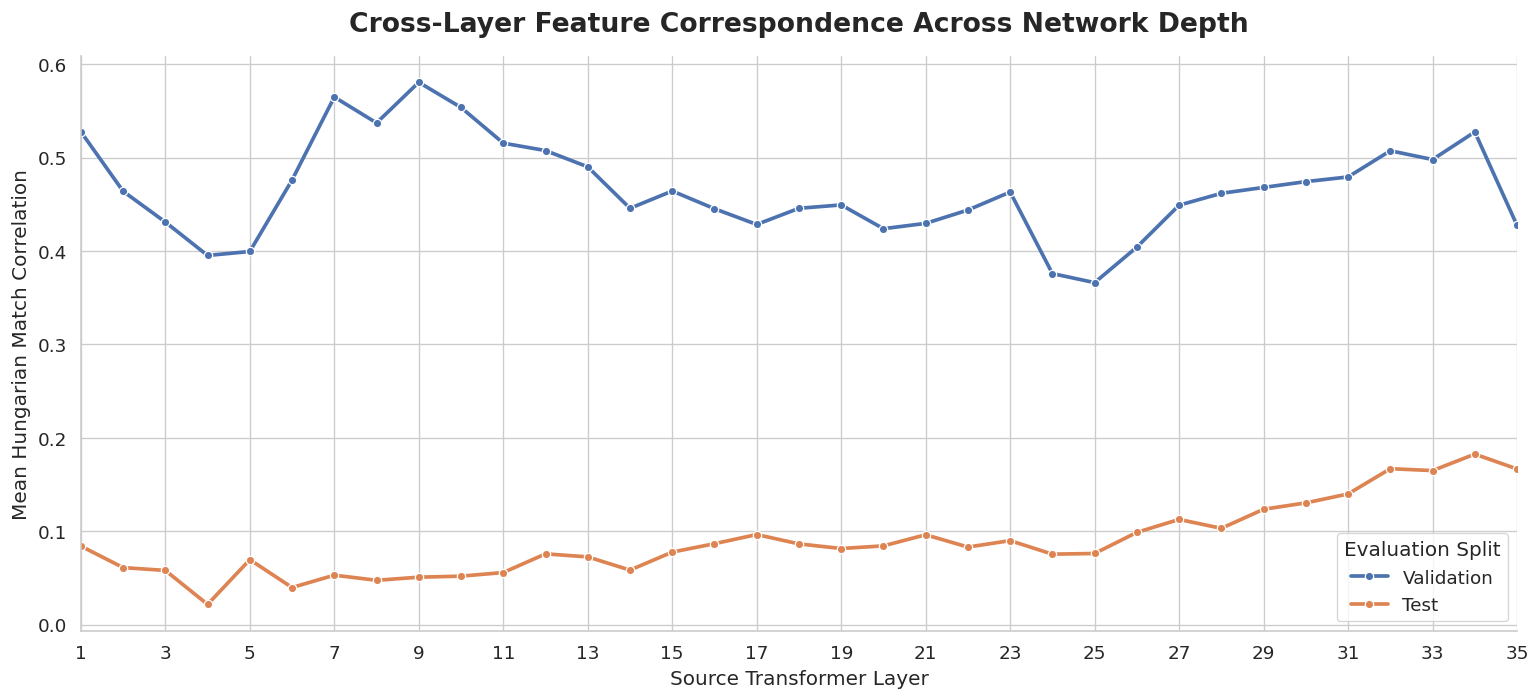

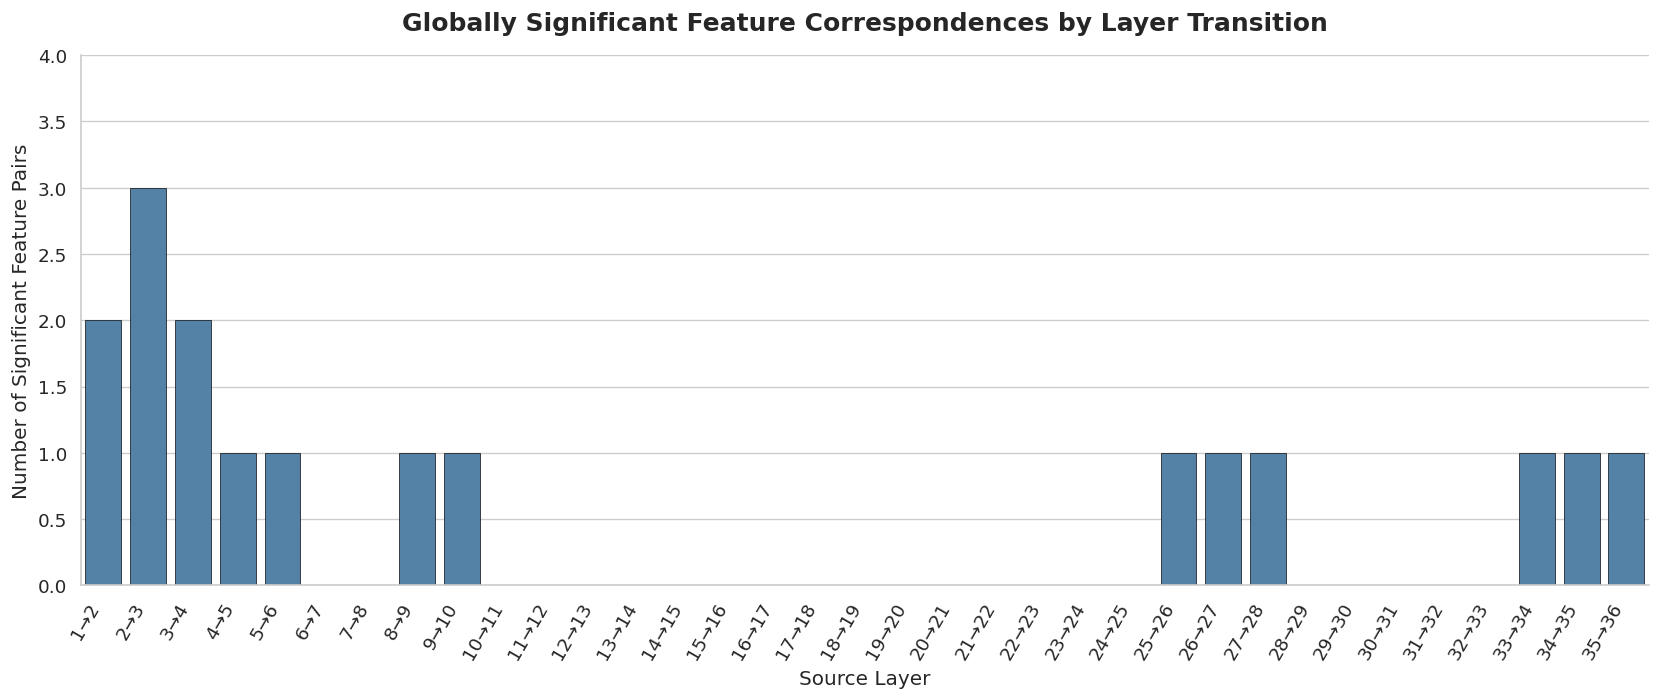

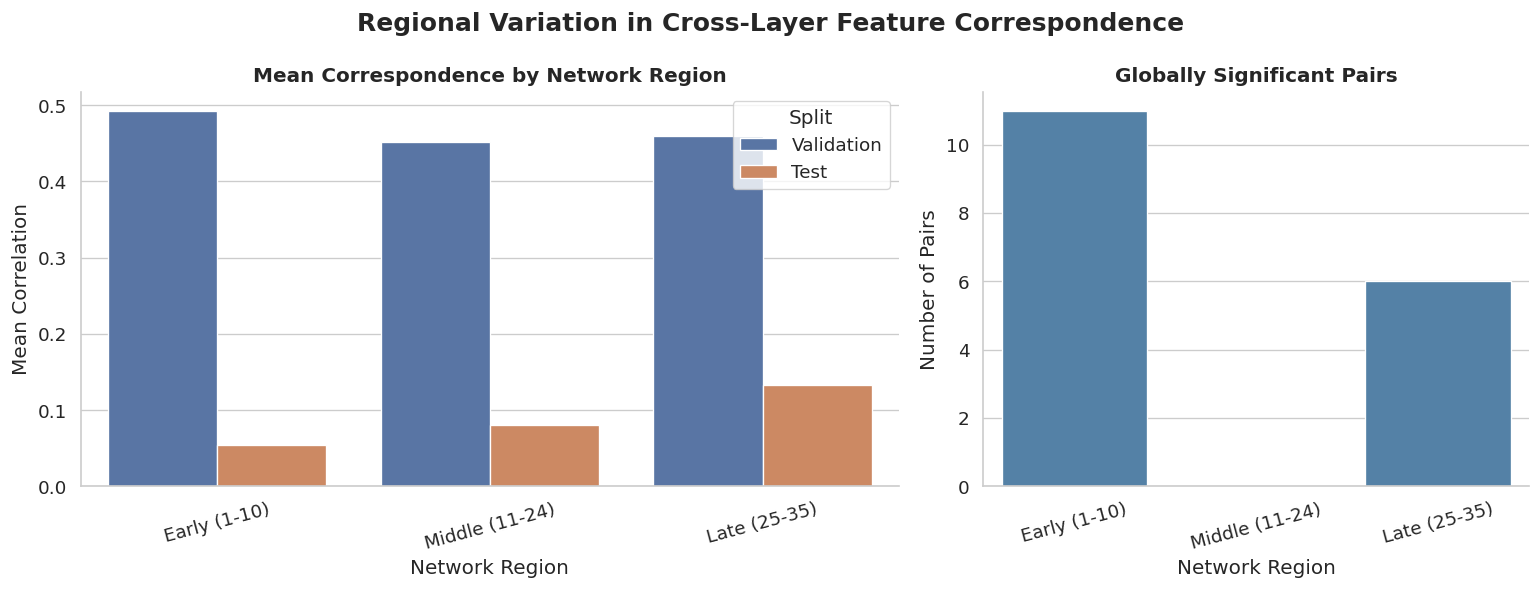

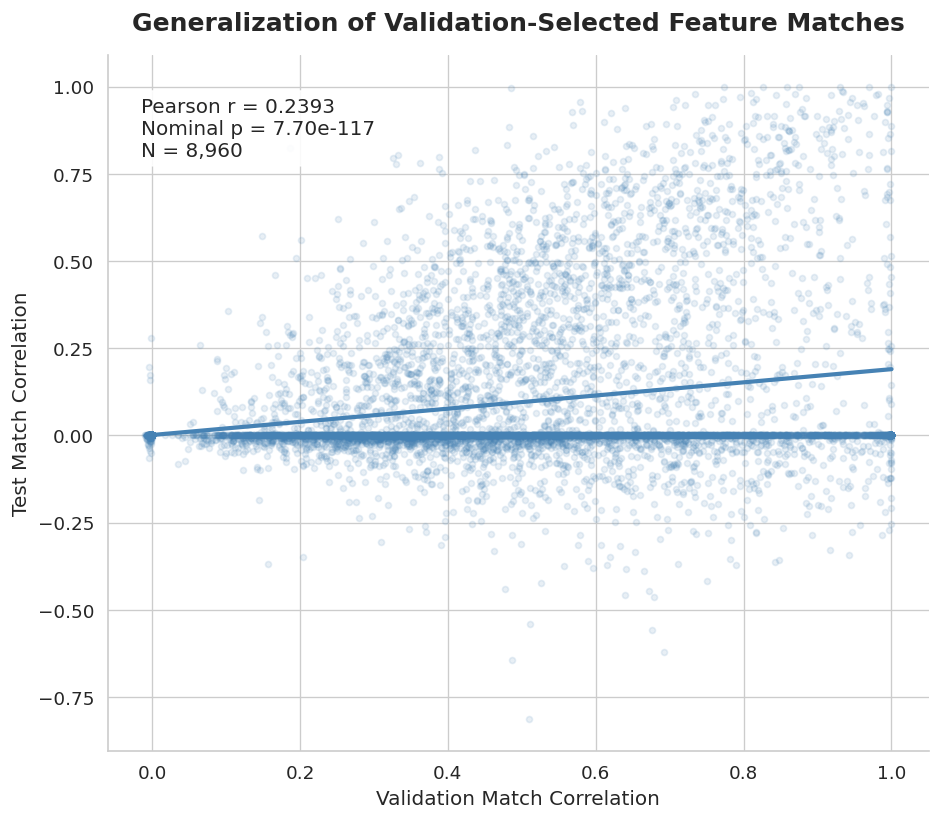


TEST 1 FIGURES GENERATED
Total matched pairs: 8,960
Globally significant pairs: 17
Validation-test Pearson r: 0.2393
Nominal Pearson p-value: 7.703e-117

Saved figures:
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/figures/Figure_1_Layer_Correlation.png
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/figures/Figure_2_Significant_Pairs.png
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/figures/Figure_3_Regional_Comparison.png
/content/drive/MyDrive/Mapping_Feature_Drift/sae_research_100k_v2/experiment_01_feature_drift/final_topic_1_global_test/figures/Figure_4_Validation_Test_Consistency.png


In [10]:

# ================================================================
# TEST 1 — PUBLICATION FIGURES
# Cross-Layer Feature Drift and Correspondence
#
# Source: final_topic_1_global_test outputs
# Libraries: pandas, seaborn, matplotlib, scipy
#
# Outputs:
#   Figure_1_Layer_Correlation.png
#   Figure_2_Significant_Pairs.png
#   Figure_3_Regional_Comparison.png
#   Figure_4_Validation_Test_Consistency.png
# ================================================================

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# ----------------------- PATHS ------------------------------------

ROOT = "/content/drive/MyDrive/Mapping_Feature_Drift"

RESULTS = os.path.join(
    ROOT,
    "sae_research_100k_v2",
    "experiment_01_feature_drift",
    "final_topic_1_global_test"
)

FIG_DIR = os.path.join(RESULTS, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# ----------------------- LOAD RESULTS -----------------------------

layers = pd.read_csv(
    os.path.join(RESULTS, "global_test_layer_results.csv")
)

regions = pd.read_csv(
    os.path.join(RESULTS, "global_test_region_results.csv")
)

pairs = pd.read_csv(
    os.path.join(RESULTS, "global_test_pair_results.csv")
)

# ----------------------- STYLE ------------------------------------

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.25
)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.labelweight": "medium",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ================================================================
# FIGURE 1 — LAYER-WISE VALIDATION VS TEST CORRELATION
# ================================================================

plot_layers = layers.melt(
    id_vars=["source_layer", "target_layer"],
    value_vars=[
        "mean_validation_corr",
        "mean_test_corr"
    ],
    var_name="split",
    value_name="mean_correlation"
)

plot_layers["split"] = plot_layers["split"].map({
    "mean_validation_corr": "Validation",
    "mean_test_corr": "Test"
})

plt.figure(figsize=(13, 6))

ax = sns.lineplot(
    data=plot_layers,
    x="source_layer",
    y="mean_correlation",
    hue="split",
    marker="o",
    linewidth=2.2,
    markersize=5
)

ax.set_title(
    "Cross-Layer Feature Correspondence Across Network Depth",
    fontsize=16,
    pad=15
)
ax.set_xlabel("Source Transformer Layer")
ax.set_ylabel("Mean Hungarian Match Correlation")

ax.set_xticks(range(1, 36, 2))
ax.set_xlim(1, 35)
ax.legend(title="Evaluation Split", frameon=True)

plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "Figure_1_Layer_Correlation.png"),
    bbox_inches="tight"
)
plt.show()
plt.close()

# ================================================================
# FIGURE 2 — GLOBALLY SIGNIFICANT PAIRS BY TRANSITION
# ================================================================

plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=layers,
    x="source_layer",
    y="global_significant_pairs",
    color="steelblue",
    edgecolor="black",
    linewidth=0.4
)

ax.set_title(
    "Globally Significant Feature Correspondences by Layer Transition",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Source Layer")
ax.set_ylabel("Number of Significant Feature Pairs")

ax.set_xticks(range(35))
ax.set_xticklabels(
    [f"{i}→{i+1}" for i in range(1, 36)],
    rotation=60,
    ha="right"
)

ax.set_ylim(
    0,
    max(2, layers["global_significant_pairs"].max() + 1)
)

plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "Figure_2_Significant_Pairs.png"),
    bbox_inches="tight"
)
plt.show()
plt.close()

# ================================================================
# FIGURE 3 — REGIONAL COMPARISON
# ================================================================

regional_plot = regions.melt(
    id_vars=["region"],
    value_vars=[
        "mean_validation_corr",
        "mean_test_corr"
    ],
    var_name="split",
    value_name="mean_correlation"
)

regional_plot["split"] = regional_plot["split"].map({
    "mean_validation_corr": "Validation",
    "mean_test_corr": "Test"
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    gridspec_kw={"width_ratios": [1.5, 1]}
)

sns.barplot(
    data=regional_plot,
    x="region",
    y="mean_correlation",
    hue="split",
    ax=axes[0]
)

axes[0].set_title("Mean Correspondence by Network Region")
axes[0].set_xlabel("Network Region")
axes[0].set_ylabel("Mean Correlation")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Split")

sns.barplot(
    data=regions,
    x="region",
    y="globally_significant_pairs",
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("Globally Significant Pairs")
axes[1].set_xlabel("Network Region")
axes[1].set_ylabel("Number of Pairs")
axes[1].tick_params(axis="x", rotation=15)

plt.suptitle(
    "Regional Variation in Cross-Layer Feature Correspondence",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "Figure_3_Regional_Comparison.png"),
    bbox_inches="tight"
)
plt.show()
plt.close()

# ================================================================
# FIGURE 4 — VALIDATION VS TEST MATCH CONSISTENCY
# ================================================================

x = pairs["validation_correlation"].to_numpy()
y = pairs["test_correlation"].to_numpy()

r, p = pearsonr(x, y)

plt.figure(figsize=(8, 7))

ax = sns.regplot(
    data=pairs,
    x="validation_correlation",
    y="test_correlation",
    scatter_kws={
        "alpha": 0.12,
        "s": 13,
        "rasterized": True
    },
    line_kws={
        "linewidth": 2.5
    },
    color="steelblue",
    ci=None
)

ax.set_title(
    "Generalization of Validation-Selected Feature Matches",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Validation Match Correlation")
ax.set_ylabel("Test Match Correlation")

ax.text(
    0.04,
    0.94,
    f"Pearson r = {r:.4f}\n"
    f"Nominal p = {p:.2e}\n"
    f"N = {len(pairs):,}",
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.9
    )
)

plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "Figure_4_Validation_Test_Consistency.png"),
    bbox_inches="tight"
)
plt.show()
plt.close()

# ================================================================
# FINAL SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("TEST 1 FIGURES GENERATED")
print("=" * 65)

print(f"Total matched pairs: {len(pairs):,}")
print(
    "Globally significant pairs:",
    int(pairs["significant_global_fwer_005"].sum())
)
print(f"Validation-test Pearson r: {r:.4f}")
print(f"Nominal Pearson p-value: {p:.3e}")

print("\nSaved figures:")
for filename in sorted(os.listdir(FIG_DIR)):
    if filename.endswith(".png"):
        print(os.path.join(FIG_DIR, filename))
